# 05. 方差分解

本 notebook 评估 ACRs、UMRs、proximal TEs、它们的 union 以及 genome-wide reference 的 context-specific genomic relationship matrices，并将 GSL spatial panel 与 LDAK REML 结果合并生成 Figure 4。


In [2]:
import os
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

data_dir = os.path.join(os.getcwd(), "data")
source_dir = os.path.join(data_dir, "source")
results_dir = os.path.join(data_dir, "results")
run_dir = os.path.join(os.getcwd(), "run")

partition_dir = os.path.join(results_dir, "partition")
os.makedirs(partition_dir, exist_ok=True)

载入landraces信息

In [3]:
vcf_file = os.path.join(data_dir, "source", "landraces_GxE_miss0.5_maf0.05_het0.05.vcf.gz")
landraces_df = pd.read_csv(os.path.join(data_dir, "source", "landraces_metadata.csv"))

载入具有GxE表型的样本信息

In [4]:
phenotypes_df = pd.read_csv(os.path.join(data_dir, "source", "Bernardino_2024_GxE_phenotypes.csv"))
predict_sample_ids = phenotypes_df['LIB'].tolist()

载入contexts设定

In [5]:
site_context_df = pd.read_hdf(os.path.join(data_dir, "results", "site_contexts.genome.maf0.05.h5"), key="df")
site_context_df['genome'] = True

载入envGWAS结果

In [6]:
import numpy as np

env_id_list = ["bio18", "gsl", "al", "striga"]
env_metadata_df = pd.read_csv(os.path.join(data_dir, "source", "envir_metadata.csv"))
env_labels = {}
for env_id in env_id_list:
    env_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}.gemma", f"{env_id}.gemma.gwas_df.h5"), key="df")
    env_df = env_df[['ID', 'P_WALD']]
    env_df = env_df.rename(columns={'P_WALD': env_id})
    env_df[env_id] = -np.log10(env_df[env_id])
    site_context_df = site_context_df.merge(env_df, on='ID', how='left')
    env_labels[env_id] = env_metadata_df.loc[env_metadata_df['env_id'] == env_id, 'description'].values[0]

载入contrasts设定

In [7]:
import json

contrasts_settings_json_file = os.path.join(os.getcwd(), "config", "contrasts_settings.json")
with open(contrasts_settings_json_file, "r") as f:
    contrasts_settings = json.load(f)

向site_context_df中增加Pi、Recomb、MAF等信息

## 1. Genomic compartments

### 1.1 genic_2kb_vs_genome

In [35]:
from src.partition import run_partition_contrast

contrast_id = "genic_2kb_vs_genome"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)


[genic_2kb_vs_genome] Final outputs already exist, skipping contrast.


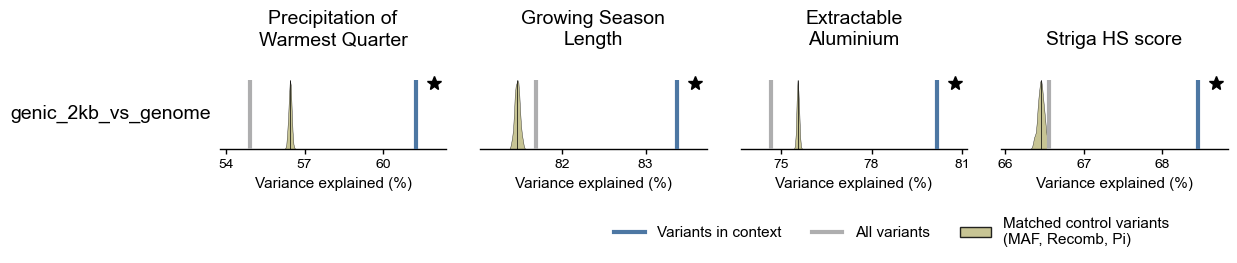

In [36]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

## 2. Gene Structure

### 2.1 在基因区内部比较

#### 2.1.1 upstream_2kb_vs_genic

In [37]:
from src.partition import run_partition_contrast

contrast_id = "upstream_2kb_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)


[upstream_2kb_vs_genic] Final outputs already exist, skipping contrast.


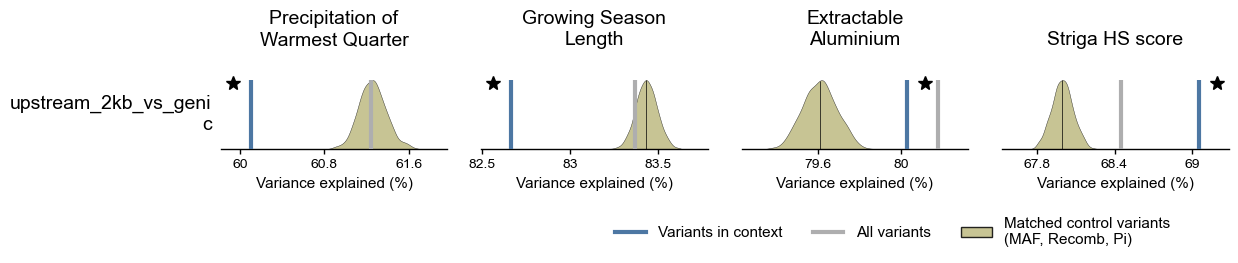

In [38]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

#### 2.1.2 five_prime_UTR_vs_genic

In [39]:
from src.partition import run_partition_contrast

contrast_id = "five_prime_UTR_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)


[five_prime_UTR_vs_genic] Final outputs already exist, skipping contrast.


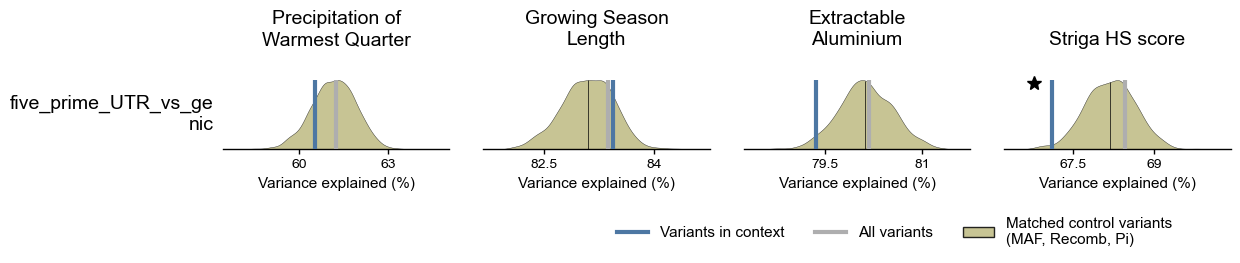

In [40]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

#### 2.1.3 CDS_vs_genic

In [41]:
from src.partition import run_partition_contrast

contrast_id = "CDS_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)


[CDS_vs_genic] Final outputs already exist, skipping contrast.


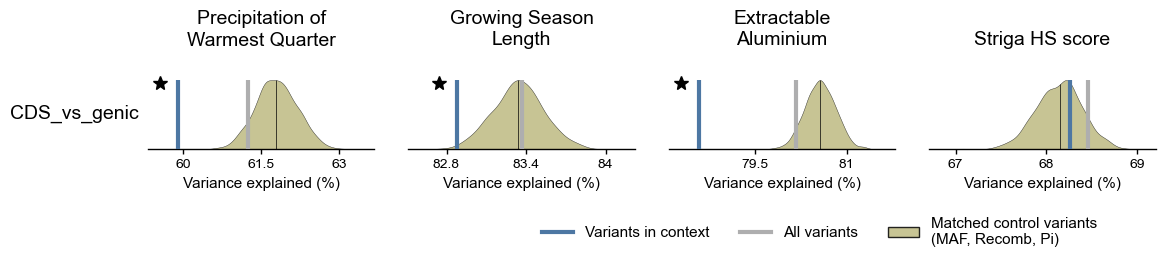

In [42]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

#### 2.1.4 intron_vs_genic

In [43]:
from src.partition import run_partition_contrast

contrast_id = "intron_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)


[intron_vs_genic] Final outputs already exist, skipping contrast.


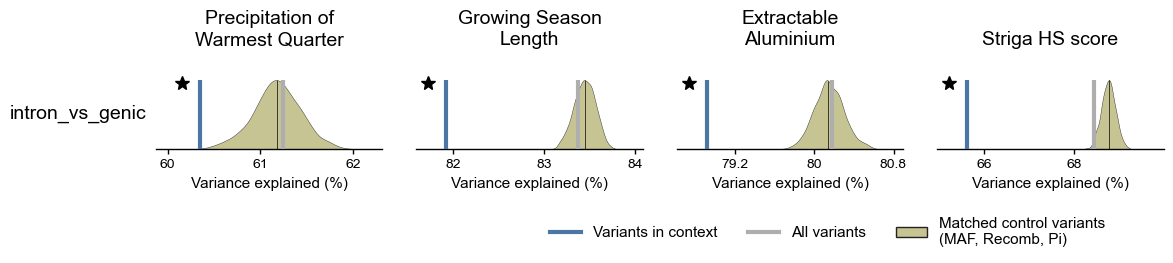

In [44]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

#### 2.1.5 three_prime_UTR_vs_genic

In [45]:
from src.partition import run_partition_contrast

contrast_id = "three_prime_UTR_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)


[three_prime_UTR_vs_genic] Final outputs already exist, skipping contrast.


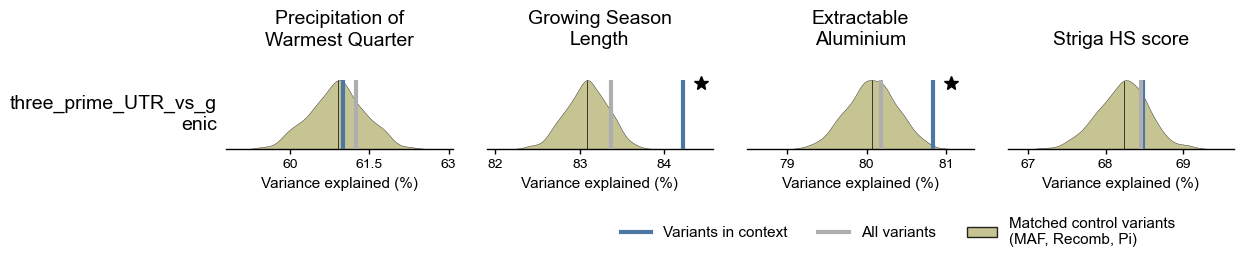

In [46]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

#### 2.1.6 downstream_2kb_vs_genic

In [47]:
from src.partition import run_partition_contrast

contrast_id = "downstream_2kb_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)


[downstream_2kb_vs_genic] Final outputs already exist, skipping contrast.


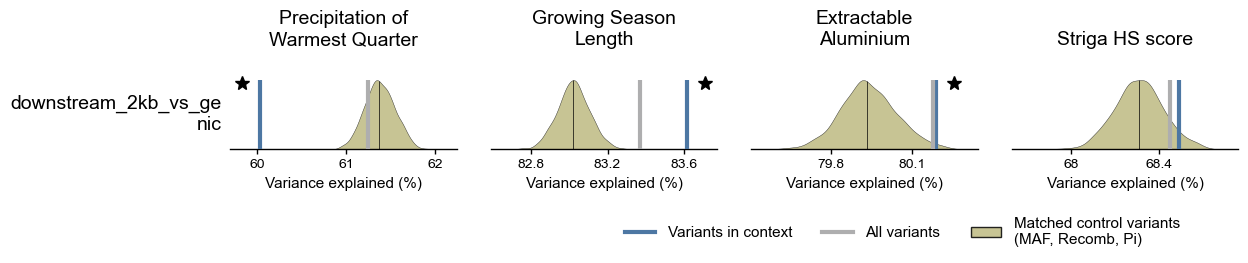

In [48]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

## 3. Epigenomic features

### 3.1 ACR_vs_genome

In [ ]:
from src.partition import run_partition_contrast

contrast_id = "ACR_vs_genome"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed, debug=True)


[ACR_vs_genome] Final outputs already exist, skipping contrast.


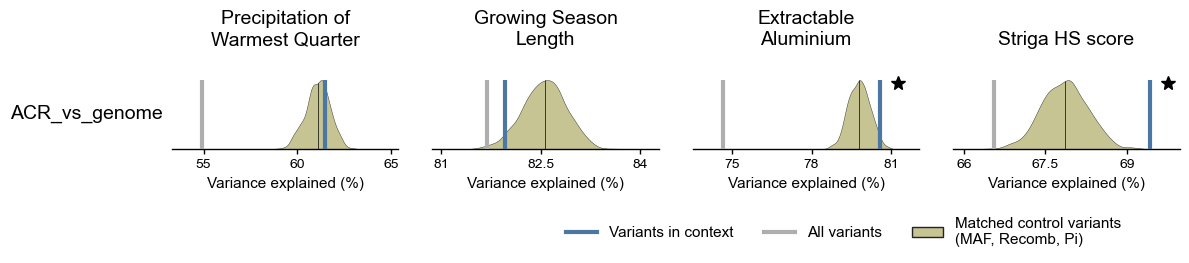

In [34]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

### 3.2 UMR_vs_genome

In [50]:
from src.partition import run_partition_contrast

contrast_id = "UMR_vs_genome"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)


[UMR_vs_genome] Final outputs already exist, skipping contrast.


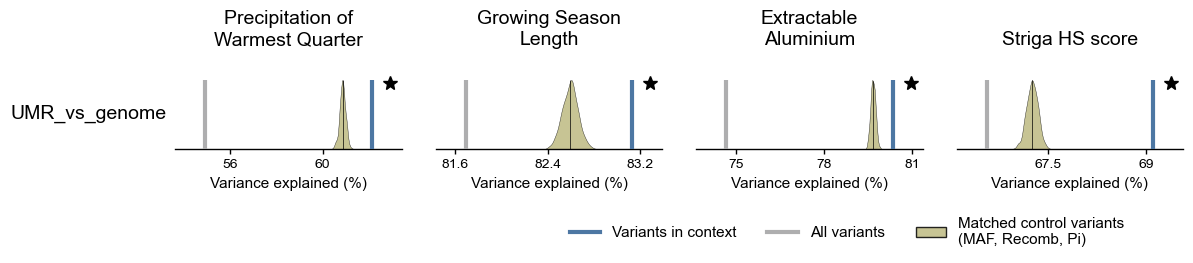

In [51]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

## 4. Genic proximal and distal

### 4.1 proximal_TE_vs_proximal

In [52]:
from src.partition import run_partition_contrast

contrast_id = "proximal_TE_vs_proximal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)


[proximal_TE_vs_proximal] Final outputs already exist, skipping contrast.


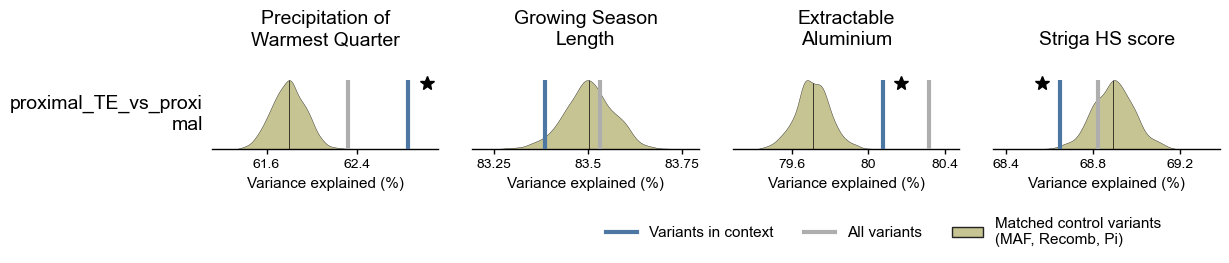

In [53]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

### 4.3 proximal_ACR_vs_proximal

In [54]:
from src.partition import run_partition_contrast

contrast_id = "proximal_ACR_vs_proximal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)


[proximal_ACR_vs_proximal] Final outputs already exist, skipping contrast.


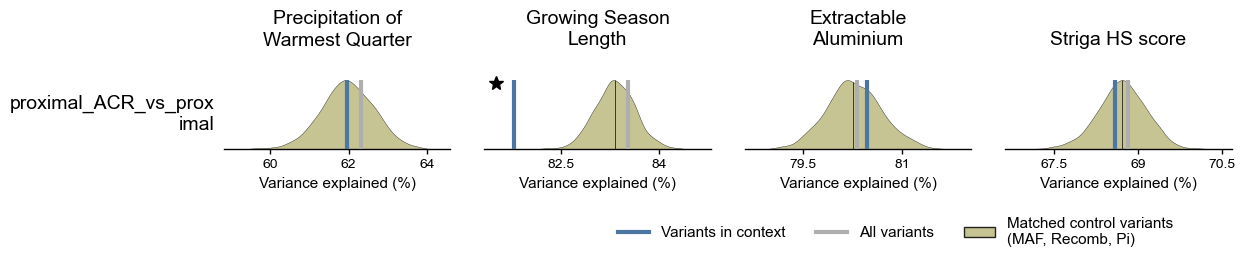

In [55]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

### 4.4 distal_ACR_vs_distal

In [ ]:
from src.partition import run_partition_contrast

contrast_id = "distal_ACR_vs_distal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)

Running enrichment for contrast: distal_ACR_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (genome - genic_proximal) & ACR
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast distal_ACR_vs_distal, skipping.
LD overlap results already exist for contrast distal_ACR_vs_distal. Skipping calculation.


### 4.5 proximal_UMR_vs_proximal

In [ ]:
from src.partition import run_partition_contrast

contrast_id = "proximal_UMR_vs_proximal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)

Running enrichment for contrast: proximal_UMR_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: UMR & genic_proximal
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast proximal_UMR_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_UMR_vs_proximal. Skipping calculation.


### 4.6 distal_UMR_vs_distal

In [ ]:
from src.partition import run_partition_contrast

contrast_id = "distal_UMR_vs_distal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)

Running enrichment for contrast: distal_UMR_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (genome - genic_proximal) & UMR
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast distal_UMR_vs_distal, skipping.
LD overlap results already exist for contrast distal_UMR_vs_distal. Skipping calculation.


### 4.7 proximal_ACR_not_TE_vs_proximal_TE_not_ACR

In [ ]:
from src.partition import run_partition_contrast

contrast_id = "proximal_ACR_not_TE_vs_proximal_TE_not_ACR"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)

Running enrichment for contrast: proximal_ACR_not_TE_vs_proximal_TE_not_ACR
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (ACR & genic_proximal) - TE
  Background set: (TE & genic_proximal) - ACR
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast proximal_ACR_not_TE_vs_proximal_TE_not_ACR, skipping.
LD overlap results already exist for contrast proximal_ACR_not_TE_vs_proximal_TE_not_ACR. Skipping calculation.


## 5. Evolutionary conservation & Population genetics

### 5.3 Phylogenetic conservation (PhyloP)

#### 5.3.1 non_CEs

In [ ]:
from src.partition import run_partition_contrast

contrast_id = "non_CEs"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)

Running enrichment for contrast: non_CEs
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: non_CEs & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 20.5s | 48.73/s | ETA 0.0s
1000 permutations with pool_num=40: 20.83 s (48.00 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.6s | 103.86/s | ETA 0.0s
1000 permutations with pool_num=40: 9.96 s (100.41 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 11.1s | 90.21/s | ETA 0.0s
1000 permutations with pool_num=40: 11.44 s (87.44 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.7s | 130.70/s | ETA 0.0s
1000 permutations with pool_num=40: 7.97 s (125.45 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.3s | 136.48/s | ETA 0.0s
1000 permutations with pool_num=40: 7.66 s (130.60 permutations/s)
Permutations: 1000/1000 (1

#### 5.3.2 conserved_sites

In [ ]:
from src.partition import run_partition_contrast

contrast_id = "conserved_sites"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)

Running enrichment for contrast: conserved_sites
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: conserved_sites & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 20.3s | 49.16/s | ETA 0.0s
1000 permutations with pool_num=40: 20.78 s (48.11 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 10.0s | 100.33/s | ETA 0.0s
1000 permutations with pool_num=40: 10.32 s (96.89 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 10.0s | 99.56/s | ETA 0.0s
1000 permutations with pool_num=40: 10.38 s (96.34 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.2s | 108.22/s | ETA 0.0s
1000 permutations with pool_num=40: 9.57 s (104.50 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.9s | 126.31/s | ETA 0.0s
1000 permutations with pool_num=40: 8.23 s (121.44 permutations/s)
Permutati

#### 5.3.3 neutral_sites

In [ ]:
from src.partition import run_partition_contrast

contrast_id = "neutral_sites"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)

Running enrichment for contrast: neutral_sites
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: neutral_sites & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 24.3s | 41.12/s | ETA 0.0s
1000 permutations with pool_num=40: 24.79 s (40.34 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.1s | 110.28/s | ETA 0.0s
1000 permutations with pool_num=40: 9.39 s (106.47 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.5s | 105.32/s | ETA 0.0s
1000 permutations with pool_num=40: 9.83 s (101.77 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.7s | 129.47/s | ETA 0.0s
1000 permutations with pool_num=40: 8.04 s (124.41 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.3s | 137.35/s | ETA 0.0s
1000 permutations with pool_num=40: 7.61 s (131.42 permutations/s)
Permutations: 

#### 5.3.4 accelerated_sites

In [ ]:
from src.partition import run_partition_contrast

contrast_id = "accelerated_sites"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed)

Running enrichment for contrast: accelerated_sites
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: accelerated_sites & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 21.5s | 46.59/s | ETA 0.0s
1000 permutations with pool_num=40: 21.88 s (45.69 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 10.0s | 100.19/s | ETA 0.0s
1000 permutations with pool_num=40: 10.26 s (97.44 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 11.2s | 89.51/s | ETA 0.0s
1000 permutations with pool_num=40: 11.48 s (87.10 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.3s | 120.03/s | ETA 0.0s
1000 permutations with pool_num=40: 8.65 s (115.61 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.2s | 121.29/s | ETA 0.0s
1000 permutations with pool_num=40: 8.55 s (117.00 permutations/s)
Permu